<a href="https://colab.research.google.com/github/pramodhvijay6-cmd/CBL-Deep-Learning-Image-Classification-Challenge/blob/main/CBL_Deep_Learning_Image_Classification_Challenge_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!git clone --depth 1 https://github.com/vinayprabhu/Kannada_MNIST.git
!find Kannada_MNIST -type f \( -name "*.npz" -o -name "*.csv" -o -name "*.npy" \) | head -50

Cloning into 'Kannada_MNIST'...
remote: Enumerating objects: 326, done.
remote: Counting objects: 100% (326/326), done.
remote: Compressing objects: 100% (309/309), done.
remote: Total 326 (delta 17), reused 323 (delta 17), pack-reused 0 (from 0)
Receiving objects: 100% (326/326), 150.65 MiB | 17.16 MiB/s, done.
Resolving deltas: 100% (17/17), done.
Updating files: 100% (299/299), done.
Kannada_MNIST/data/output_tensors/y_dig_mnist_10k.npy
Kannada_MNIST/data/output_tensors/y_Ka_mnist_userwise.npy
Kannada_MNIST/data/output_tensors/sanity_check_3.npy
Kannada_MNIST/data/output_tensors/y_Kannada_mnist_10k_RWC.npy
Kannada_MNIST/data/output_tensors/sanity_check_3_10k_RWC.npy
Kannada_MNIST/data/output_tensors/y_Kannada_mnist.npy
Kannada_MNIST/data/output_tensors/y_train_KaMNIST_wc.npy
Kannada_MNIST/data/output_tensors/y_test_KaMNIST_wc.npy
Kannada_MNIST/data/output_tensors/synthetic/seed_allfonts_kannada.npy
Kannada_MNIST/data/output_tensors/synthetic/seed_lohit_kannada.npy
Kannada_MNIST/data

In [ ]:
!find Kannada_MNIST -type f \( -name "*.npz" -o -name "*.csv" -o -name "*.npy" -o -name "*.zip" \)

Kannada_MNIST/data/output_tensors/y_dig_mnist_10k.npy
Kannada_MNIST/data/output_tensors/y_Ka_mnist_userwise.npy
Kannada_MNIST/data/output_tensors/sanity_check_3.npy
Kannada_MNIST/data/output_tensors/y_Kannada_mnist_10k_RWC.npy
Kannada_MNIST/data/output_tensors/sanity_check_3_10k_RWC.npy
Kannada_MNIST/data/output_tensors/y_Kannada_mnist.npy
Kannada_MNIST/data/output_tensors/y_train_KaMNIST_wc.npy
Kannada_MNIST/data/output_tensors/y_test_KaMNIST_wc.npy
Kannada_MNIST/data/output_tensors/synthetic/seed_allfonts_kannada.npy
Kannada_MNIST/data/output_tensors/synthetic/seed_lohit_kannada.npy
Kannada_MNIST/data/output_tensors/synthetic/seednames_allfonts_kannada.npy
Kannada_MNIST/data/output_tensors/MNIST_format/X_kannada_MNIST_test.npz
Kannada_MNIST/data/output_tensors/MNIST_format/y_kannada_MNIST_train.npz
Kannada_MNIST/data/output_tensors/MNIST_format/y_kannada_MNIST_test.npz
Kannada_MNIST/data/output_tensors/MNIST_format/y_dig_MNIST.npz
Kannada_MNIST/data/output_tensors/MNIST_format/X_kann

In [ ]:
import numpy as np, matplotlib.pyplot as plt
import tensorflow as tf, sys

SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)
print("Python", sys.version.split()[0], "| TF", tf.__version__)

base = "Kannada_MNIST/data/output_tensors/MNIST_format/"
X_train = np.load(base + "X_kannada_MNIST_train.npy")
y_train = np.load(base + "y_kannada_MNIST_train.npy")
X_test  = np.load(base + "X_kannada_MNIST_test.npy")
y_test  = np.load(base + "y_kannada_MNIST_test.npy")
X_dig   = np.load(base + "X_dig_MNIST.npy")
y_dig   = np.load(base + "y_dig_MNIST.npy")

for name, a in [("X_train", X_train), ("y_train", y_train),
                ("X_test", X_test), ("y_test", y_test),
                ("X_dig", X_dig), ("y_dig", y_dig)]:
    print(f"{name:8s} shape={a.shape} dtype={a.dtype} min={a.min()} max={a.max()}")

Python 3.13.16 | TF 2.21.0
X_train  shape=(60000, 28, 28) dtype=uint8 min=0 max=255
y_train  shape=(60000,) dtype=uint8 min=0 max=9
X_test   shape=(10000, 28, 28) dtype=uint8 min=0 max=255
y_test   shape=(10000,) dtype=uint8 min=0 max=9
X_dig    shape=(10240, 28, 28) dtype=uint8 min=0 max=255
y_dig    shape=(10240,) dtype=uint8 min=0 max=9


train {0: 6000, 1: 6000, 2: 6000, 3: 6000, 4: 6000, 5: 6000, 6: 6000, 7: 6000, 8: 6000, 9: 6000}
test {0: 1000, 1: 1000, 2: 1000, 3: 1000, 4: 1000, 5: 1000, 6: 1000, 7: 1000, 8: 1000, 9: 1000}
dig {0: 1024, 1: 1024, 2: 1024, 3: 1024, 4: 1024, 5: 1024, 6: 1024, 7: 1024, 8: 1024, 9: 1024}


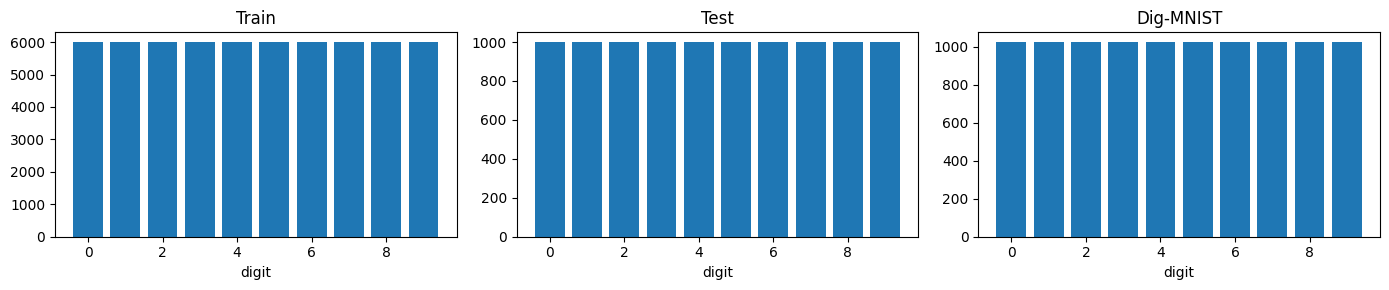

In [ ]:
for name, labels in [("train", y_train), ("test", y_test), ("dig", y_dig)]:
    vals, counts = np.unique(labels, return_counts=True)
    print(name, dict(zip(vals.tolist(), counts.tolist())))

# bar plot for your report
fig, ax = plt.subplots(1, 3, figsize=(14, 3))
for a, (name, labels) in zip(ax, [("Train", y_train), ("Test", y_test), ("Dig-MNIST", y_dig)]):
    vals, counts = np.unique(labels, return_counts=True)
    a.bar(vals, counts); a.set_title(name); a.set_xlabel("digit")
plt.tight_layout(); plt.show()

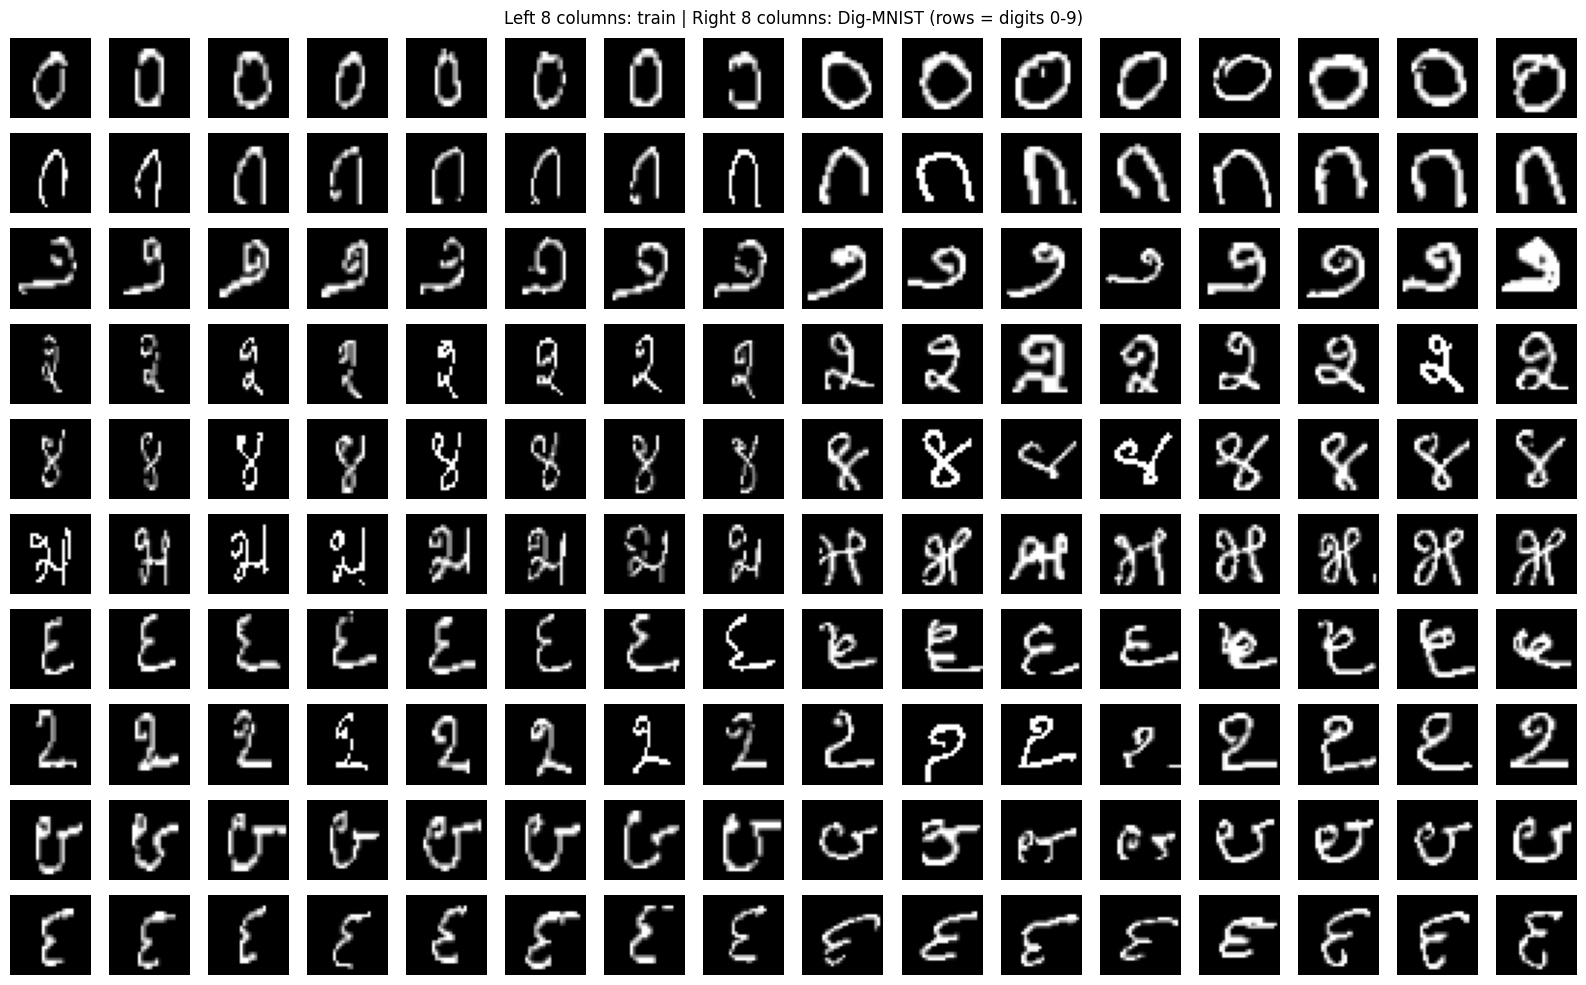

In [ ]:
fig, axes = plt.subplots(10, 16, figsize=(16, 10))
for c in range(10):
    for j, (imgs, labs) in enumerate([(X_train, y_train), (X_dig, y_dig)]):
        idx = np.where(labs == c)[0][:8]
        for k, i in enumerate(idx):
            ax = axes[c, j*8 + k]
            ax.imshow(imgs[i].reshape(28, 28), cmap="gray"); ax.axis("off")
plt.suptitle("Left 8 columns: train | Right 8 columns: Dig-MNIST (rows = digits 0-9)")
plt.tight_layout(); plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

# ensure (N, 28, 28), scale to 0-1, add channel dim
X_train = (X_train.astype("float32") / 255.0)[..., None]
X_test  = (X_test.astype("float32")  / 255.0)[..., None]
X_dig   = (X_dig.astype("float32")   / 255.0)[..., None]

# 90/10 stratified split of train into train and validation
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.10, stratify=y_train, random_state=SEED)

print("train     :", X_tr.shape, y_tr.shape)
print("validation:", X_val.shape, y_val.shape)
print("test      :", X_test.shape, y_test.shape)
print("Dig-MNIST :", X_dig.shape, y_dig.shape)
print("val per-class:", np.bincount(y_val))

# save for reproducibility
np.savez_compressed("split_ps41.npz", X_tr=X_tr, y_tr=y_tr, X_val=X_val, y_val=y_val)

train     : (54000, 28, 28, 1) (54000,)
validation: (6000, 28, 28, 1) (6000,)
test      : (10000, 28, 28, 1) (10000,)
Dig-MNIST : (10240, 28, 28, 1) (10240,)
val per-class: [600 600 600 600 600 600 600 600 600 600]


In [ ]:
from tensorflow.keras import layers, models

def build_cnn():
    m = models.Sequential([
        layers.Input(shape=(28, 28, 1)),

        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Dropout(0.25),

        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Dropout(0.25),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.4),
        layers.Dense(10, activation="softmax"),
    ])
    return m

model = build_cnn()
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 468,714 (1.79 MB)

 Trainable params: 468,266 (1.79 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
import time

model = build_cnn()
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

cb = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2,
                                     restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1),
]

t0 = time.time()
hist_base = model.fit(X_tr, y_tr,
                      validation_data=(X_val, y_val),
                      epochs=5, batch_size=256,
                      callbacks=cb, verbose=2)
train_time_base = time.time() - t0
print(f"Training time: {train_time_base/60:.1f} min")

model.save("baseline_ps41.keras")

Epoch 1/5
211/211 - 238s - 1s/step - accuracy: 0.9504 - loss: 0.1660 - val_accuracy: 0.1018 - val_loss: 2.2987 - learning_rate: 0.0010
Epoch 2/5
211/211 - 261s - 1s/step - accuracy: 0.9882 - loss: 0.0411 - val_accuracy: 0.5057 - val_loss: 1.1535 - learning_rate: 0.0010
Epoch 3/5
211/211 - 237s - 1s/step - accuracy: 0.9920 - loss: 0.0293 - val_accuracy: 0.9925 - val_loss: 0.0316 - learning_rate: 0.0010
Epoch 4/5
211/211 - 258s - 1s/step - accuracy: 0.9931 - loss: 0.0231 - val_accuracy: 0.9947 - val_loss: 0.0183 - learning_rate: 0.0010
Epoch 5/5
211/211 - 240s - 1s/step - accuracy: 0.9946 - loss: 0.0191 - val_accuracy: 0.9962 - val_loss: 0.0130 - learning_rate: 0.0010
Training time: 20.6 min


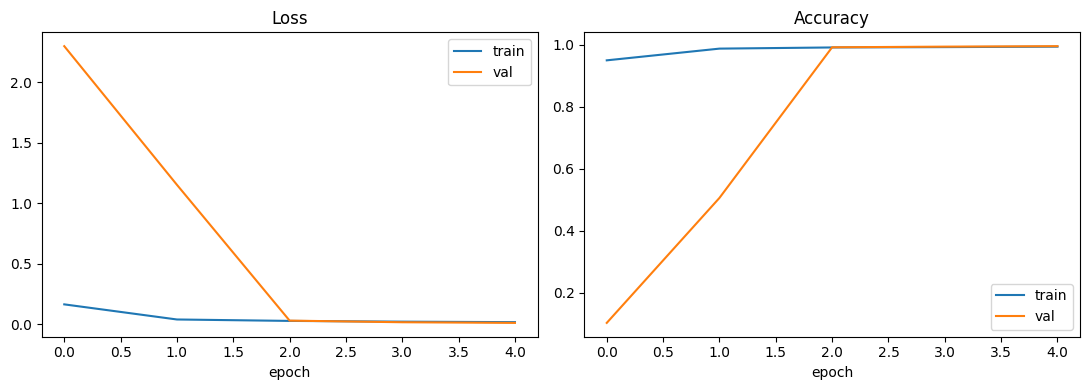

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist_base.history["loss"], label="train")
ax[0].plot(hist_base.history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(hist_base.history["accuracy"], label="train")
ax[1].plot(hist_base.history["val_accuracy"], label="val")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
from tensorflow.keras import layers, models

augment = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.RandomRotation(0.08),               # about ±15 degrees
    layers.RandomZoom(0.15),
    layers.RandomTranslation(0.1, 0.1),
], name="augment")

model_aug = models.Sequential([augment, build_cnn()])
model_aug.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])

cb = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2,
                                     restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1),
]

t0 = time.time()
hist_aug = model_aug.fit(X_tr, y_tr,
                         validation_data=(X_val, y_val),
                         epochs=6, batch_size=256,
                         callbacks=cb, verbose=2)
train_time_aug = time.time() - t0
print(f"Training time: {train_time_aug/60:.1f} min")
model_aug.save("augmented_ps41.keras")

Epoch 1/6
211/211 - 242s - 1s/step - accuracy: 0.8569 - loss: 0.4489 - val_accuracy: 0.2123 - val_loss: 4.0122 - learning_rate: 0.0010
Epoch 2/6
211/211 - 238s - 1s/step - accuracy: 0.9617 - loss: 0.1276 - val_accuracy: 0.4380 - val_loss: 2.4499 - learning_rate: 0.0010
Epoch 3/6
211/211 - 238s - 1s/step - accuracy: 0.9724 - loss: 0.0906 - val_accuracy: 0.9717 - val_loss: 0.1007 - learning_rate: 0.0010
Epoch 4/6
211/211 - 262s - 1s/step - accuracy: 0.9783 - loss: 0.0726 - val_accuracy: 0.9922 - val_loss: 0.0283 - learning_rate: 0.0010
Epoch 5/6
211/211 - 240s - 1s/step - accuracy: 0.9808 - loss: 0.0631 - val_accuracy: 0.9682 - val_loss: 0.1042 - learning_rate: 0.0010
Epoch 6/6
211/211 - 242s - 1s/step - accuracy: 0.9848 - loss: 0.0490 - val_accuracy: 0.9913 - val_loss: 0.0304 - learning_rate: 5.0000e-04
Training time: 24.7 min


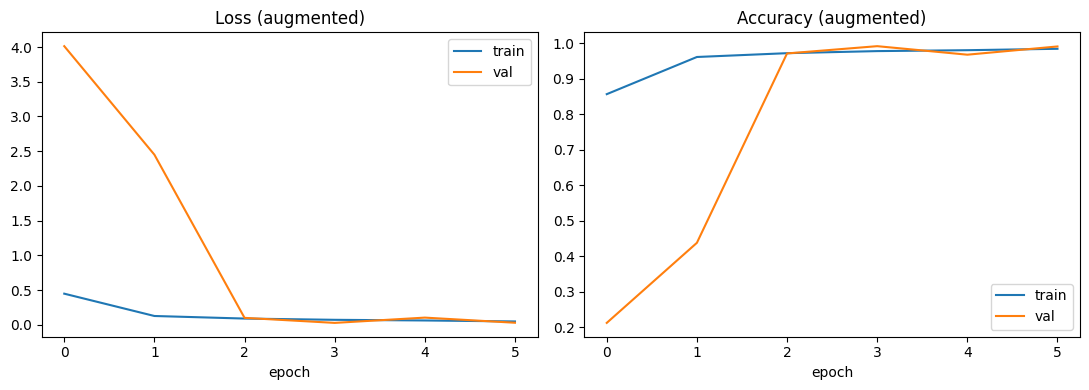

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist_aug.history["loss"], label="train")
ax[0].plot(hist_aug.history["val_loss"], label="val")
ax[0].set_title("Loss (augmented)"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(hist_aug.history["accuracy"], label="train")
ax[1].plot(hist_aug.history["val_accuracy"], label="val")
ax[1].set_title("Accuracy (augmented)"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

models_dict = {"Baseline": model, "Augmented": model_aug}
sets = {"Test (10,000)": (X_test, y_test), "Dig-MNIST (10,240)": (X_dig, y_dig)}

preds, rows = {}, []
for mname, m in models_dict.items():
    for sname, (X, y) in sets.items():
        p = np.argmax(m.predict(X, batch_size=512, verbose=0), axis=1)
        preds[(mname, sname)] = p
        rows.append([mname, sname,
                     round(accuracy_score(y, p), 4),
                     round(f1_score(y, p, average="macro"), 4)])

import pandas as pd
results = pd.DataFrame(rows, columns=["Model", "Evaluation set", "Accuracy", "Macro F1"])
print(results.to_string(index=False))

    Model     Evaluation set  Accuracy  Macro F1
 Baseline      Test (10,000)    0.9740    0.9740
 Baseline Dig-MNIST (10,240)    0.7812    0.7798
Augmented      Test (10,000)    0.9590    0.9588
Augmented Dig-MNIST (10,240)    0.8466    0.8458


In [ ]:
for mname in models_dict:
    for sname, (X, y) in sets.items():
        print(f"\n===== {mname} | {sname} =====")
        print(classification_report(y, preds[(mname, sname)], digits=4))


===== Baseline | Test (10,000) =====
              precision    recall  f1-score   support

           0     0.9734    0.9530    0.9631      1000
           1     0.9521    0.9940    0.9726      1000
           2     0.9911    0.9970    0.9940      1000
           3     0.9969    0.9740    0.9853      1000
           4     0.9266    0.9970    0.9605      1000
           5     0.9958    0.9380    0.9660      1000
           6     0.9606    0.9750    0.9677      1000
           7     0.9893    0.9230    0.9550      1000
           8     0.9901    0.9970    0.9935      1000
           9     0.9716    0.9920    0.9817      1000

    accuracy                         0.9740     10000
   macro avg     0.9747    0.9740    0.9740     10000
weighted avg     0.9747    0.9740    0.9740     10000


===== Baseline | Dig-MNIST (10,240) =====
              precision    recall  f1-score   support

           0     0.8361    0.6328    0.7204      1024
           1     0.9006    0.8145    0.8554      10

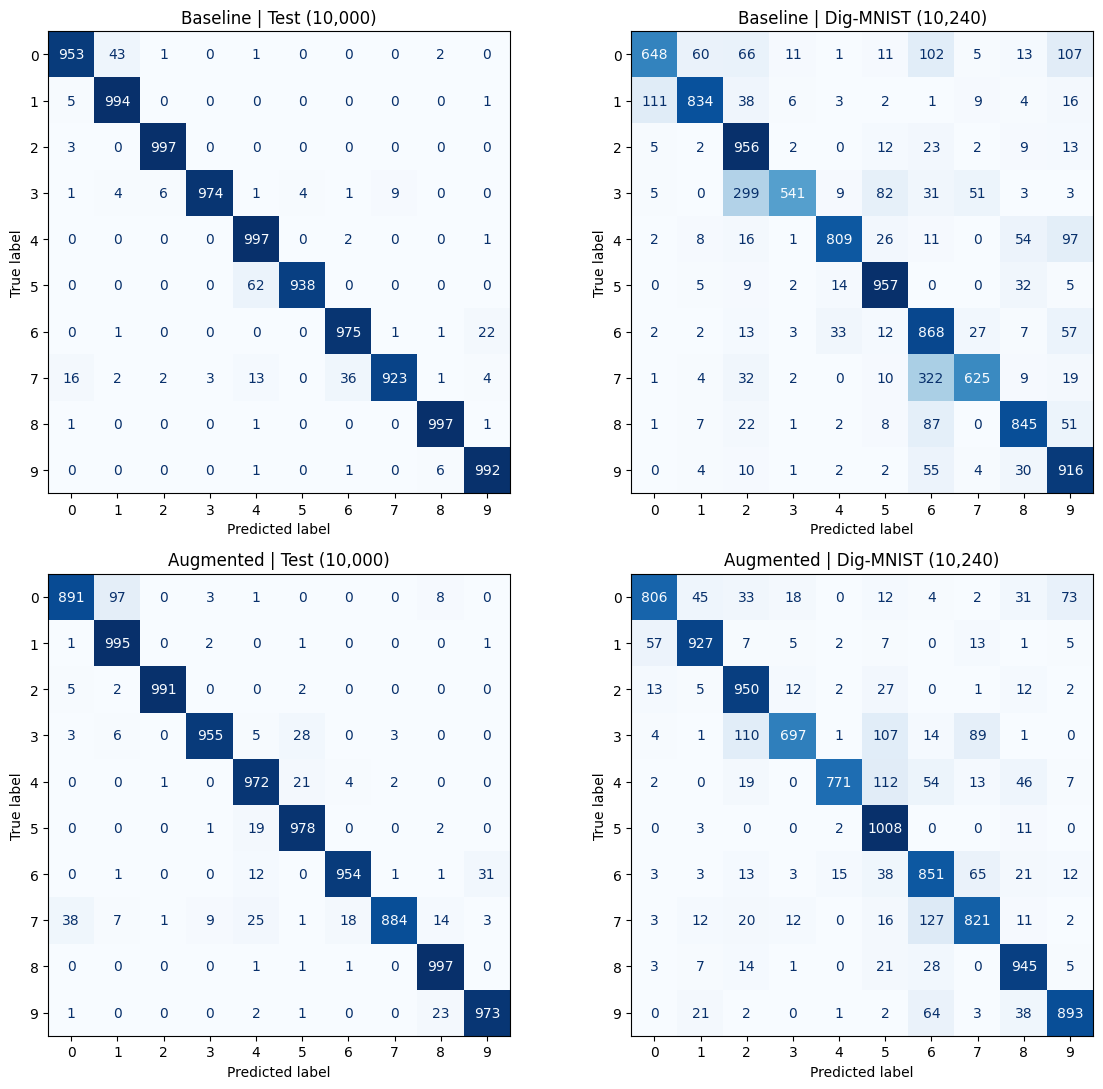

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))
for ax, mname, sname in [(axes[0,0], "Baseline", "Test (10,000)"),
                         (axes[0,1], "Baseline", "Dig-MNIST (10,240)"),
                         (axes[1,0], "Augmented", "Test (10,000)"),
                         (axes[1,1], "Augmented", "Dig-MNIST (10,240)")]:
    y = sets[sname][1]
    cm = confusion_matrix(y, preds[(mname, sname)])
    ConfusionMatrixDisplay(cm).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{mname} | {sname}")
plt.tight_layout(); plt.show()

In [ ]:
best = "Augmented"   # change to "Baseline" if it has the higher validation accuracy
y = y_dig
cm = confusion_matrix(y, preds[(best, "Dig-MNIST (10,240)")])
np.fill_diagonal(cm, 0)
top = np.dstack(np.unravel_index(np.argsort(-cm.ravel())[:5], cm.shape))[0]
for t, p in top:
    print(f"true {t} -> predicted {p}: {cm[t, p]} images")

true 7 -> predicted 6: 127 images
true 4 -> predicted 5: 112 images
true 3 -> predicted 2: 110 images
true 3 -> predicted 5: 107 images
true 3 -> predicted 7: 89 images


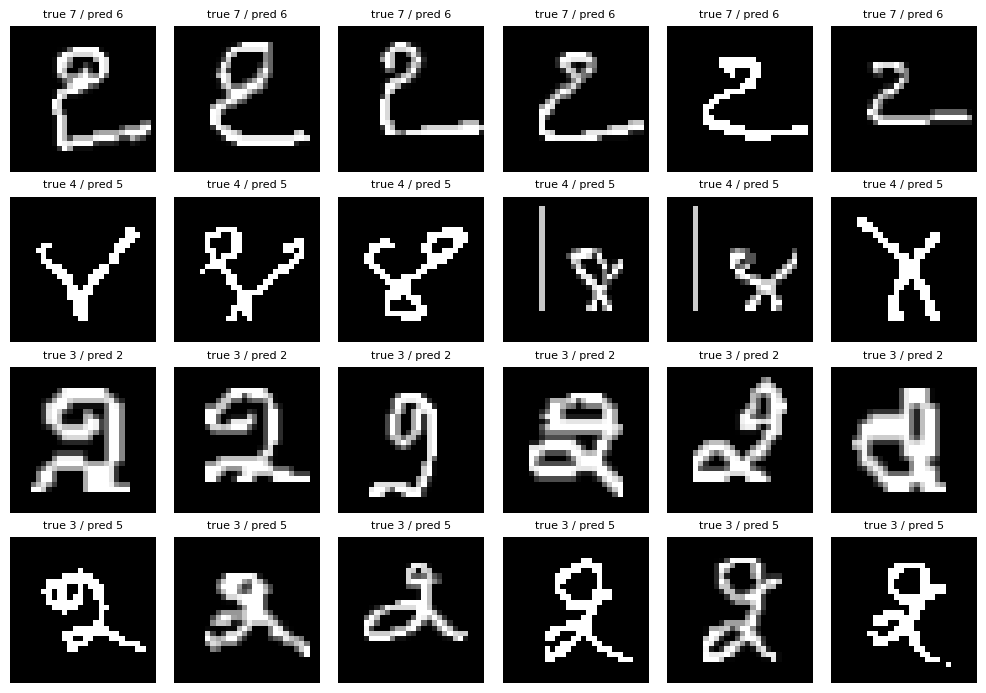

In [ ]:
best = "Augmented"
p = preds[(best, "Dig-MNIST (10,240)")]

pairs = [(7, 6), (4, 5), (3, 2), (3, 5)]
fig, axes = plt.subplots(len(pairs), 6, figsize=(10, 7))
for r, (t, q) in enumerate(pairs):
    idx = np.where((y_dig == t) & (p == q))[0][:6]
    for c in range(6):
        axes[r, c].axis("off")
        if c < len(idx):
            axes[r, c].imshow(X_dig[idx[c], :, :, 0], cmap="gray")
            axes[r, c].set_title(f"true {t} / pred {q}", fontsize=8)
plt.tight_layout(); plt.show()

KeyError: "Exception encountered when calling Functional.call().\n\n\x1b[1m133005958121904\x1b[0m\n\nArguments received by Functional.call():\n  • inputs=array([[[[0.        ],\n         [0.        ],\n         [0.        ],\n         [0.        ],\n         [0.        ],\n         [0.        ],\n         [0.        ],\n         [0.        ],\n         [0.        ],\n         [0.        ],\n         [0.        ],\n         [0.        ],\n         [0.        ],\n         [0.        ],\n         [0.        ],\n         [0.        ],\n         [0.        ],\n         [0.        ],\n         [0.        ],\n         [0.        ],\n         [0.        ],\n         [0.        ],\n         [0.        ],\n         [0.        ],\n         [0.        ],\n         [0.        ],\n         [0.        ],\n         [0.        ]],\n\n        [[0.        ],\n         [0.        ],\n         [0.        ],\n         [0.        ],\n         [0.        ],\n         [0.        ],\n         [0.        ],\n   

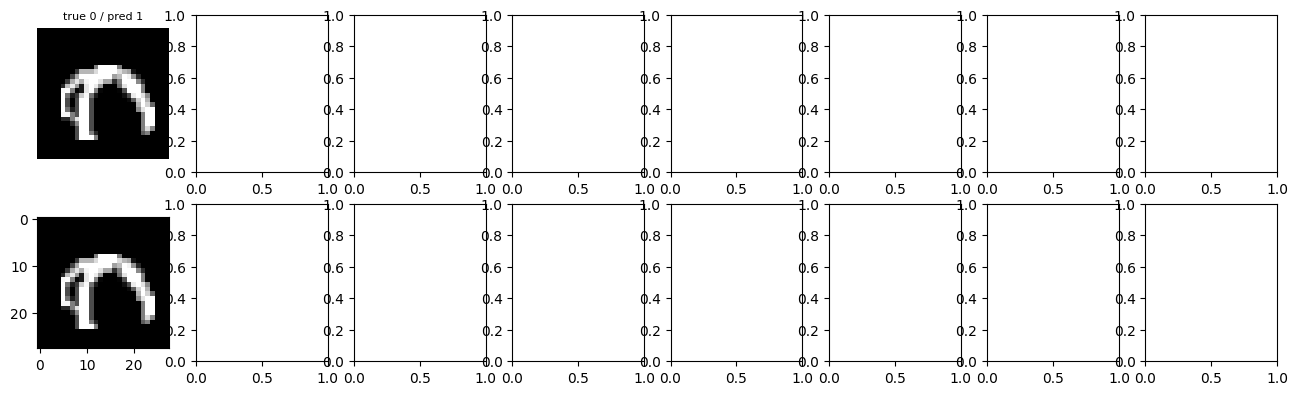

In [ ]:
inner = model_aug.layers[1]                      # the trained CNN without the augmentation layers
conv_name = [l.name for l in inner.layers
             if isinstance(l, tf.keras.layers.Conv2D)][-1]

def gradcam(m, img):
    gm = tf.keras.Model(m.inputs, [m.get_layer(conv_name).output, m.output])
    with tf.GradientTape() as tape:
        conv, pred = gm(img[None])
        score = pred[:, tf.argmax(pred[0])]
    grads = tape.gradient(score, conv)
    w = tf.reduce_mean(grads, axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv * w[:, None, None, :], axis=-1))[0]
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return tf.image.resize(cam[..., None], (28, 28)).numpy()[..., 0]

wrong = np.where(y_dig != p)[0]
rng = np.random.default_rng(SEED)
pick = rng.choice(wrong, 8, replace=False)

fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for k, i in enumerate(pick):
    axes[0, k].imshow(X_dig[i, :, :, 0], cmap="gray"); axes[0, k].axis("off")
    axes[0, k].set_title(f"true {y_dig[i]} / pred {p[i]}", fontsize=8)
    axes[1, k].imshow(X_dig[i, :, :, 0], cmap="gray")
    axes[1, k].imshow(gradcam(inner, X_dig[i]), cmap="jet", alpha=0.45); axes[1, k].axis("off")
plt.tight_layout(); plt.show()

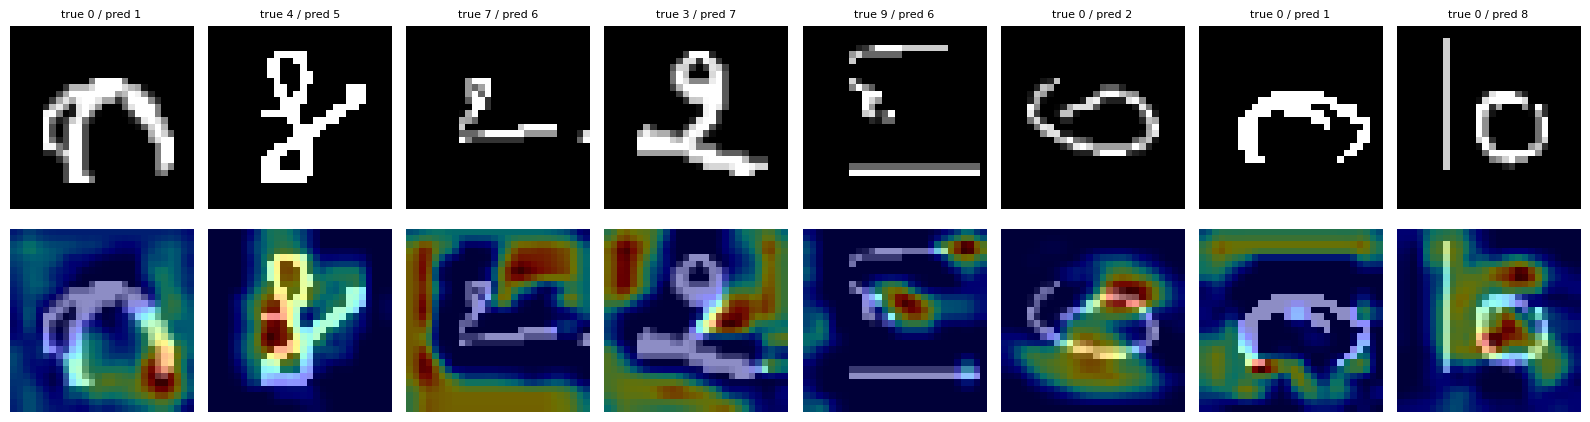

In [ ]:
inner = model_aug.layers[1]          # the trained CNN (no augmentation layers)
conv_layers = [l for l in inner.layers if isinstance(l, tf.keras.layers.Conv2D)]
last_conv = conv_layers[-1]
last_idx = inner.layers.index(last_conv)

def gradcam(img):
    x = tf.convert_to_tensor(img[None], dtype=tf.float32)
    with tf.GradientTape() as tape:
        h = x
        for i, layer in enumerate(inner.layers):
            h = layer(h, training=False)
            if i == last_idx:
                conv = h
                tape.watch(conv)
        pred = h
        score = pred[:, tf.argmax(pred[0])]
    grads = tape.gradient(score, conv)
    w = tf.reduce_mean(grads, axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv * w[:, None, None, :], axis=-1))[0]
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return tf.image.resize(cam[..., None], (28, 28)).numpy()[..., 0]

wrong = np.where(y_dig != p)[0]
rng = np.random.default_rng(SEED)
pick = rng.choice(wrong, 8, replace=False)

fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for k, i in enumerate(pick):
    axes[0, k].imshow(X_dig[i, :, :, 0], cmap="gray"); axes[0, k].axis("off")
    axes[0, k].set_title(f"true {y_dig[i]} / pred {p[i]}", fontsize=8)
    axes[1, k].imshow(X_dig[i, :, :, 0], cmap="gray")
    axes[1, k].imshow(gradcam(X_dig[i]), cmap="jet", alpha=0.45); axes[1, k].axis("off")
plt.tight_layout(); plt.show()

In [ ]:
   print("Baseline  val_acc:", max(hist_base.history["val_accuracy"]), "| time (min):", train_time_base/60)
   print("Augmented val_acc:", max(hist_aug.history["val_accuracy"]),  "| time (min):", train_time_aug/60)

Baseline  val_acc: 0.9961666464805603 | time (min): 20.579730192820232
Augmented val_acc: 0.9921666383743286 | time (min): 24.71203553279241


In [ ]:
import numpy as np, pandas as pd, tensorflow as tf, matplotlib.pyplot as plt, os, time
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

SAVE = ""   # saves in the Colab folder (no Google Drive needed)
SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)
print("TF", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

if not os.path.exists("Kannada_MNIST"):
    os.system("git clone --depth 1 https://github.com/vinayprabhu/Kannada_MNIST.git")
base = "Kannada_MNIST/data/output_tensors/MNIST_format/"
f = lambda n: np.load(base + n)
X_train = (f("X_kannada_MNIST_train.npy").astype("float32")/255.0)[..., None]
y_train = f("y_kannada_MNIST_train.npy")
X_test  = (f("X_kannada_MNIST_test.npy").astype("float32")/255.0)[..., None]
y_test  = f("y_kannada_MNIST_test.npy")
X_dig   = (f("X_dig_MNIST.npy").astype("float32")/255.0)[..., None]
y_dig   = f("y_dig_MNIST.npy")

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.10, stratify=y_train, random_state=SEED)
print(X_tr.shape, X_val.shape, X_test.shape, X_dig.shape)

def build_cnn():
    return models.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(), layers.Dropout(0.25),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(), layers.Dropout(0.25),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.BatchNormalization(), layers.Dropout(0.4),
        layers.Dense(10, activation="softmax"),
    ])

def compile_(m):
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def callbacks():
    return [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1)]

# baseline
model = compile_(build_cnn())
t0 = time.time()
hist_base = model.fit(X_tr, y_tr, validation_data=(X_val, y_val),
                      epochs=5, batch_size=256, callbacks=callbacks(), verbose=2)
train_time_base = time.time() - t0
model.save(SAVE + "baseline_ps41.keras")

# augmented
augment = models.Sequential([layers.Input(shape=(28, 28, 1)),
                             layers.RandomRotation(0.08),
                             layers.RandomZoom(0.15),
                             layers.RandomTranslation(0.1, 0.1)], name="augment")
model_aug = compile_(models.Sequential([augment, build_cnn()]))
t0 = time.time()
hist_aug = model_aug.fit(X_tr, y_tr, validation_data=(X_val, y_val),
                         epochs=6, batch_size=256, callbacks=callbacks(), verbose=2)
train_time_aug = time.time() - t0
model_aug.save(SAVE + "augmented_ps41.keras")

print("\nBaseline  best val_acc:", max(hist_base.history["val_accuracy"]), "| time (min):", train_time_base/60)
print("Augmented best val_acc:", max(hist_aug.history["val_accuracy"]),  "| time (min):", train_time_aug/60)

TF 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
(54000, 28, 28, 1) (6000, 28, 28, 1) (10000, 28, 28, 1) (10240, 28, 28, 1)
Epoch 1/5
211/211 - 29s - 137ms/step - accuracy: 0.9487 - loss: 0.1776 - val_accuracy: 0.5310 - val_loss: 1.5117 - learning_rate: 0.0010
Epoch 2/5
211/211 - 3s - 16ms/step - accuracy: 0.9874 - loss: 0.0441 - val_accuracy: 0.9618 - val_loss: 0.2204 - learning_rate: 0.0010
Epoch 3/5
211/211 - 3s - 16ms/step - accuracy: 0.9913 - loss: 0.0306 - val_accuracy: 0.9927 - val_loss: 0.0298 - learning_rate: 0.0010
Epoch 4/5
211/211 - 3s - 16ms/step - accuracy: 0.9929 - loss: 0.0245 - val_accuracy: 0.9953 - val_loss: 0.0155 - learning_rate: 0.0010
Epoch 5/5
211/211 - 3s - 16ms/step - accuracy: 0.9940 - loss: 0.0195 - val_accuracy: 0.9947 - val_loss: 0.0147 - learning_rate: 0.0010
Epoch 1/6
211/211 - 14s - 66ms/step - accuracy: 0.8644 - loss: 0.4307 - val_accuracy: 0.1038 - val_loss: 3.1419 - learning_rate: 0.0010
Epoch 2/6
211/211 - 6s - 28m

In [ ]:
import time, numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

best = "Baseline" if max(hist_base.history["val_accuracy"]) >= max(hist_aug.history["val_accuracy"]) else "Augmented"
m = model if best == "Baseline" else model_aug
hist = hist_base if best == "Baseline" else hist_aug
print("Main model:", best, "| parameters:", m.count_params())

# inference time per image (batch of 1000, after warm-up)
m.predict(X_test[:1000], batch_size=1000, verbose=0)
t0 = time.time(); m.predict(X_test[:1000], batch_size=1000, verbose=0)
print(f"Inference: {(time.time()-t0)/1000*1000:.3f} ms/image (T4 GPU, batched)")

for sname, (X, y) in sets.items():
    print(f"\n===== {best} | {sname} =====")
    print(classification_report(y, preds[(best, sname)], digits=4))

# Fig 1: learning curves
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
for a, k, t in [(ax[0], "loss", "Loss"), (ax[1], "accuracy", "Accuracy")]:
    a.plot(hist.history[k], label="train"); a.plot(hist.history["val_" + k], label="val")
    a.set_title(t); a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.savefig("fig1_curves.png", dpi=200); plt.show()

# Fig 2: confusion matrices (test and Dig-MNIST)
fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
for a, (sname, (X, y)) in zip(ax, sets.items()):
    ConfusionMatrixDisplay(confusion_matrix(y, preds[(best, sname)])).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title(f"{best} | {sname}")
plt.tight_layout(); plt.savefig("fig2_confusion.png", dpi=200); plt.show()

# top confused pairs on Dig-MNIST
cm = confusion_matrix(y_dig, preds[(best, "Dig-MNIST (10,240)")]); np.fill_diagonal(cm, 0)
for t, q in np.dstack(np.unravel_index(np.argsort(-cm.ravel())[:5], cm.shape))[0]:
    print(f"true {t} -> predicted {q}: {cm[t, q]} images")

# Grad-CAM and misclassified images (Baseline = plain Sequential)
inner = m if best == "Baseline" else m.layers[1]
last_idx = inner.layers.index([l for l in inner.layers if isinstance(l, tf.keras.layers.Conv2D)][-1])
def gradcam(img):
    x = tf.convert_to_tensor(img[None], dtype=tf.float32)
    with tf.GradientTape() as tape:
        h = x
        for i, layer in enumerate(inner.layers):
            h = layer(h, training=False)
            if i == last_idx: conv = h; tape.watch(conv)
        score = h[:, tf.argmax(h[0])]
    g = tape.gradient(score, conv); w = tf.reduce_mean(g, axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv * w[:, None, None, :], axis=-1))[0]
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return tf.image.resize(cam[..., None], (28, 28)).numpy()[..., 0]

p = preds[(best, "Dig-MNIST (10,240)")]
pick = np.random.default_rng(SEED).choice(np.where(y_dig != p)[0], 8, replace=False)
fig, ax = plt.subplots(2, 8, figsize=(16, 4.5))
for k, i in enumerate(pick):
    ax[0, k].imshow(X_dig[i, :, :, 0], cmap="gray"); ax[0, k].axis("off")
    ax[0, k].set_title(f"true {y_dig[i]} / pred {p[i]}", fontsize=8)
    ax[1, k].imshow(X_dig[i, :, :, 0], cmap="gray")
    ax[1, k].imshow(gradcam(X_dig[i]), cmap="jet", alpha=0.45); ax[1, k].axis("off")
plt.tight_layout(); plt.savefig("fig3_gradcam.png", dpi=200); plt.show()

Main model: Baseline | parameters: 468714
Inference: 0.227 ms/image (T4 GPU, batched)


NameError: name 'sets' is not defined

In [ ]:
from sklearn.metrics import accuracy_score, f1_score
models_dict = {"Baseline": model, "Augmented": model_aug}
sets = {"Test (10,000)": (X_test, y_test), "Dig-MNIST (10,240)": (X_dig, y_dig)}

preds, rows = {}, []
for mname, m_ in models_dict.items():
    for sname, (X, y) in sets.items():
        p_ = np.argmax(m_.predict(X, batch_size=512, verbose=0), axis=1)
        preds[(mname, sname)] = p_
        rows.append([mname, sname, round(accuracy_score(y, p_), 4),
                     round(f1_score(y, p_, average="macro"), 4)])
results = pd.DataFrame(rows, columns=["Model", "Evaluation set", "Accuracy", "Macro F1"])
print(results.to_string(index=False))

    Model     Evaluation set  Accuracy  Macro F1
 Baseline      Test (10,000)    0.9785    0.9785
 Baseline Dig-MNIST (10,240)    0.7755    0.7721
Augmented      Test (10,000)    0.9434    0.9436
Augmented Dig-MNIST (10,240)    0.8139    0.8162
